In [6]:
import pandas as pd
df=pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


1.Explore the data how many rows and how many columns

In [5]:
df.shape

(1338, 7)

2.Data types

In [18]:
df.dtypes


age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

3.simple statistics

In [11]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


4.how many types of sex

In [16]:
df["sex"].unique()

<StringArray>
['female', 'male']
Length: 2, dtype: str

5.check null values

In [21]:
df.isnull()

,age,sex,bmi,children,smoker,region,charges
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
1333,False,False,False,False,False,False,False
1334,False,False,False,False,False,False,False
1335,False,False,False,False,False,False,False
1336,False,False,False,False,False,False,False


6.Data visualization(SEABORN)

<Axes: xlabel='region', ylabel='Count'>

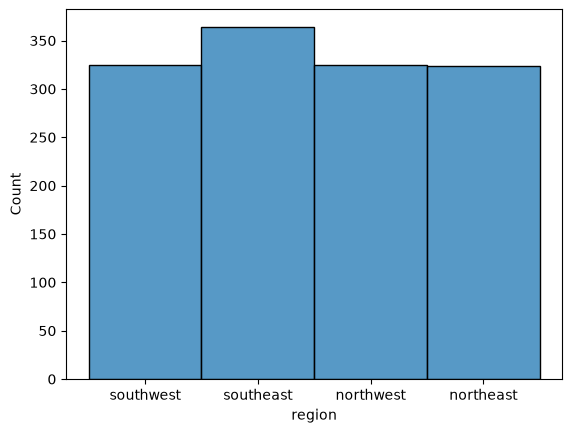

In [22]:
import seaborn as sns
sns.histplot(df["region"])

7.Data visualization(Matplotlib)

(array([574.,   0., 324.,   0., 240.,   0., 157.,   0.,  25.,  18.]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

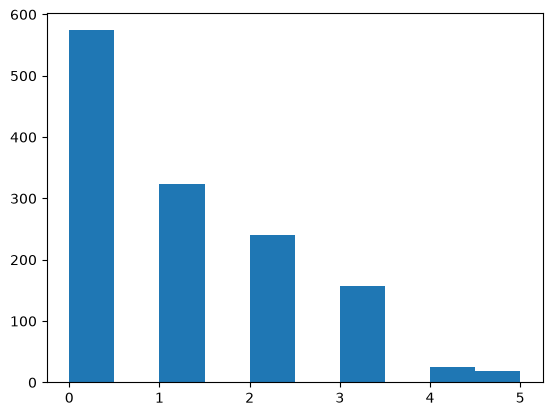

In [37]:
import matplotlib.pyplot as plt
plt.hist(df["children"])

8.Boxplot

<Axes: >

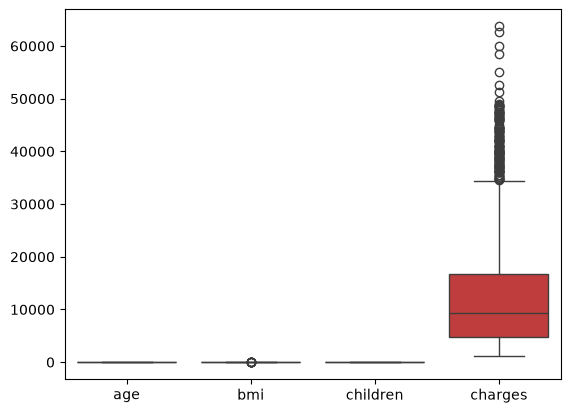

In [29]:
sns.boxplot(df)

9.print numerical features

In [53]:
#categorical=[col for col in df.columns if df[col].dtypes!="0"]
categorical = [col for col in df.columns if df[col].dtypes in ['int64','float64']]

In [54]:
df[categorical]

,age,bmi,children,charges
0,19,27.900,0,16884.92400
1,18,33.770,1,1725.55230
2,28,33.000,3,4449.46200
3,33,22.705,0,21984.47061
4,32,28.880,0,3866.85520
...,...,...,...,...
1333,50,30.970,3,10600.54830
1334,18,31.920,0,2205.98080
1335,18,36.850,0,1629.83350
1336,21,25.800,0,2007.94500


9.correration analysis

<Axes: >

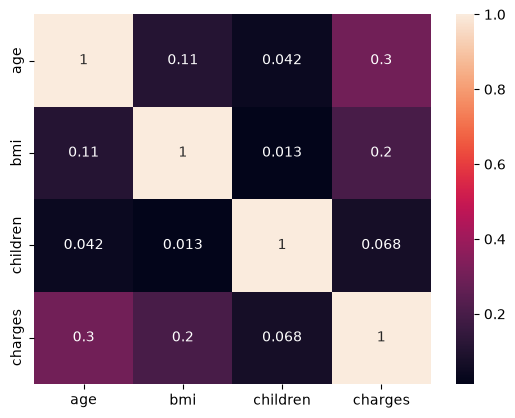

In [56]:
correl=df[categorical].corr()
sns.heatmap(correl,annot=True)

10.encoding

In [57]:
from sklearn.preprocessing import LabelEncoder

11.initialize encoder

In [62]:
enc=LabelEncoder()
df["sex"]=enc.fit_transform(df["sex"])
df["sex"].dtypes
df["sex"]

0       0
1       1
2       1
3       1
4       1
       ..
1333    1
1334    0
1335    0
1336    0
1337    0
Name: sex, Length: 1338, dtype: int64

In [66]:
df["region"]=enc.fit_transform(df["region"])
df["smoker"]=enc.fit_transform(df["smoker"])
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520


<Axes: >

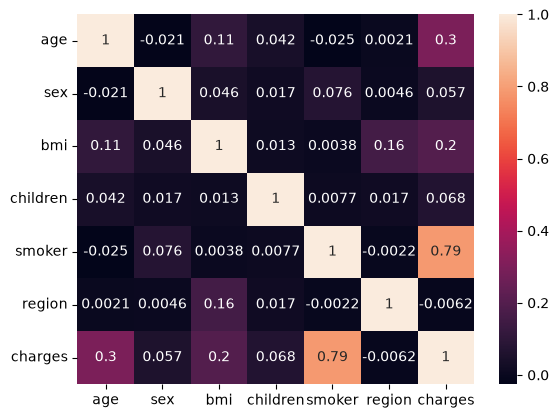

In [69]:
all_data_corr=df.corr()
sns.heatmap(all_data_corr,annot=True)

11.To make a model that predict the charges customer company
1.defining input features

In [71]:
x=df.drop("charges",axis=1)
x.head()

,age,sex,bmi,children,smoker,region
0,19,0,27.900,0,1,3
1,18,1,33.770,1,0,2
2,28,1,33.000,3,0,2
3,33,1,22.705,0,0,1
4,32,1,28.880,0,0,1


2.define the output label

In [75]:
y=df["charges"]

In [76]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=1)

3.print whole dataset

In [77]:
df.shape

(1338, 7)

4.print training features

In [78]:
x_train.shape

(1070, 6)

In [79]:
x_test.shape

(268, 6)

5.print testing features

In [80]:
y_train.shape

(1070,)

In [81]:
y_test.shape

(268,)

6.import linear regression model

In [90]:
from sklearn.linear_model import LinearRegression
Insurance_model=LinearRegression()

7.training model

In [93]:
Insurance_model.fit(x_train,y_train)
print(Insurance_model.coef_,Insurance_model.intercept_)

[  258.01557886  -244.31610607   315.08300514   412.23885375
 23766.9743197   -330.62676068] -11210.165734543418


8.let predict x_test

In [94]:
y_predicted=Insurance_model.predict(x_test)
y_predicted.shape

(268,)

9.evaluate model(using mean_squared_error,coefficient of determination(r2))

In [96]:
#calculating the coefficient of determination
from sklearn.metrics import r2_score
R2=r2_score(y_test,y_predicted)
print(R2)

0.7623224022563388


In [98]:
#minisquare error
from sklearn.metrics import mean_squared_error
mse=mean_squared_error(y_test,y_predicted)
mse

35480663.81217908

save the model

In [101]:
import joblib #library to save model
joblib.dump(Insurance_model,"My_insurance.joblib")

['My_insurance.joblib']

Access the model and use it for prediction

In [104]:
My_model=joblib.load("My_insurance.joblib")
Prediction=My_model.predict(x_test)
print(Prediction)

[ 4312.08656955 12859.49737555 12370.50358911 13549.5511475
   410.55490166 32052.76977091 13170.26923221 12248.5052133
  3713.54941225 29760.32281711 11338.50159148 17269.6492891
  8961.13430709  8184.25429812  3376.85292436 10278.37012511
  3883.36513262  6793.01504696 15270.57009799 14255.67564306
 12438.83818074 33176.73034139  9068.32669468  8835.62475682
  2922.83938461  8155.7017465   9497.57563203 11015.04509043
  7503.17666222  4307.99883589 13939.03683704  5657.88640469
 34592.37757194 26941.6112407  33661.91509295  9552.53576302
 30183.50964412 26485.52800009 15397.47566838 33857.57796843
  6575.23382913 14015.49951905 11034.83628114 14878.37537422
  4056.87355672 13036.25142266  4582.39598034 28857.50476848
  7305.25026916 14215.34197814 13570.38542044 12171.25378059
  1860.5537778   8743.00482524 25989.68277284 10318.04975471
 34486.04416316 14338.30219512  3181.55608612  6080.26510845
  6805.93170349 14850.7770469  27218.86704763  3253.69992296
 15670.34534562 11189.05910

Homework: use the gradio and make simple interface to interact with the model we developed to to day(deployment) 